# Thi thử

Một bài làm có model tốt vẫn có thể không được chấm: notebook dùng biến tạo từ ô đã xóa, file cần thiết nằm ngoài thư mục nộp, file CSV thừa cột index. Thi thử giúp phát hiện những lỗi này trước kỳ thi thật. Bài này hướng dẫn tổ chức một buổi thi thử: chạy lại từ môi trường trống tới file nộp hợp lệ, ghi nhật ký thời gian, và chữa bài để chọn việc cần luyện tiếp. Đề, chương trình chấm và tài nguyên do người tổ chức lớp chọn từ các bài đã học.

> **Mục tiêu**
>
> - Đặt điều kiện cho buổi thi thử: thời gian, tài nguyên, tài liệu, cách nộp.
> - Chạy lại bài từ đầu; nạp model trong chương trình mới.
> - Kiểm file nộp: ID, cột, miền giá trị.
> - Chữa bài để chọn việc cần luyện tiếp.

## Mô phỏng đúng điều kiện nào?

“Thi thử đúng điều kiện thật” chỉ có nghĩa khi đã biết đúng kỳ thi nào. **IOAI 2025 Individual Contest** mô tả ngày 1 tiếp nối at-home tasks và ngày 2 có bài mới. **IOAI 2026 Individual Contest** mô tả ngày 1 liên hệ về chủ đề hoặc phương pháp với at-home, ngày 2 là vấn đề chưa gặp. Cách mô tả của một năm không tự thành quy định chung cho năm sau. [Rules 2025](https://ioai-official.org/wp-content/uploads/2025/08/Contest-Rules-for-IOAI-2025-version-2.3-1.pdf), [Rules 2026](https://ioai-official.org/wp-content/uploads/2026/06/IOAI2026-Contest-Rules-and-Tehnical-Appendix.pdf).

Điều kiện còn nằm ở từng bài. Một bài của USA-NA-AIO 2026 (Vòng 2, Ngày 1) yêu cầu huấn luyện và kiểm trên GPU L4, và cho 0 điểm nếu notebook không chạy đúng trên L4 ([Part 1.4](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf#page=9)). Một bài khác của cùng vòng (Ngày 2, Problem 4) cấm mọi model pretrained, kể cả khi không dùng trọng số pretrained, và cấm gán nhãn test bằng mắt ([Problem 4](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-2-problems.pdf#page=9)). Hai ví dụ cho thấy GPU, model được dùng và cách làm hợp lệ được chốt trong đề của từng bài, không nằm ở tên cuộc thi.

Phiên **360 phút** trong bài là một cấu hình luyện do người tổ chức lớp chọn, đủ dài để luyện quyết định và mốc dừng theo một lịch. Muốn gọi buổi luyện là mô phỏng VOAI, cấu hình phải gắn với thông báo VOAI của đúng năm và vòng.

Tương tự, GPU T4 có thể chỉ là máy của lớp, không phải GPU của kỳ thi nào. Dữ liệu, package, pretrained, Internet, công cụ hỗ trợ và quyền mang mã nguồn vào thi cần được xác nhận riêng; phần nào thiếu model hay dữ liệu thì luyện bằng CPU và ghi rõ trong mô tả.

Một mô tả phiên luyện cần ngắn nhưng cụ thể, ví dụ:

- dùng các bài cũ do lớp chọn, thời gian 360 phút;
- ghi lại máy và phiên bản thư viện;
- chỉ dùng model và dữ liệu đã cấp sẵn trên máy;
- dạng nộp theo đề; scorer tự động không cho xem nhãn kín;
- không mở lời giải trước khi hết giờ.

Có mô tả đó, học sinh biết năng lực nào đang được đo và người chữa biết điều kiện nào đã khác kỳ thi mục tiêu.

**Hỏi nhanh.** Lớp có GPU T4 và chọn phiên 360 phút. Đã coi buổi luyện là khớp đầy đủ điều kiện IOAI của một năm cụ thể được chưa?

- A. Được rồi, vì cùng loại GPU và cùng thời lượng là hai điều kiện chính
- B. Được rồi, nếu model đạt accuracy bằng baseline của kỳ thi
- C. Chưa, vì còn tài nguyên được phép, dạng bài nộp và cách chấm
- D. Chưa, vì GPU T4 luôn chậm hơn GPU của mọi kỳ thi

<details><summary>Đáp án</summary>

C. Chưa, vì còn tài nguyên được phép, dạng bài nộp và cách chấm

GPU và thời lượng chỉ là hai trong nhiều điều kiện. Tài nguyên được phép, dạng bài nộp và cách chấm của đúng năm và đúng vòng thi cũng phải khớp. Accuracy bằng baseline không nói gì về điều kiện thi. T4 chậm hơn hay không cũng không quyết định, vì điều kiện được đối chiếu theo quy định và statement, không đoán theo loại GPU.

</details>

## Mốc thời gian để có một bài làm hoàn tất

Lịch 360 phút của buổi luyện chia thành năm giai đoạn, mỗi giai đoạn kết thúc bằng một điều kiện kiểm được:

| Giai đoạn | Thời gian | Xong khi |
|---|---|---|
| Đọc đề, kiểm môi trường | 30 phút | Đã ghi yêu cầu của đề |
| Dựng baseline và validation | 75 phút | Có bản nộp tối thiểu |
| Cải thiện | 195 phút | Có bằng chứng để chọn bản |
| Chạy lại bản cuối | 45 phút | Chạy lại xong từ đầu |
| Kiểm file nộp, kết thúc | 15 phút | Đọc lại file đúng schema |

Đây là phân bổ để luyện, không phải giới hạn của từng bài trong kỳ thi thật.

Tính tay: $30+75+195+45+15=360$, nên mốc đóng thí nghiệm là phút $360-45-15=300$. Nếu một lần chạy từ đầu cần 70 phút, phần 45 phút không đủ: mốc đóng phải dời xuống phút $360-70-15=275$, hoặc bản cuối phải nhẹ hơn. Vì vậy thời gian chạy lại cần đo sớm, không đợi tới lúc bắt đầu chạy lại mới biết. Một lần inference nhanh trên 10 mẫu không chứng minh thời gian end-to-end trên dữ liệu đầy đủ.

**Hỏi nhanh.** Phiên dài 360 phút. Chạy lại bản cuối từ đầu mất 70 phút, và phần kiểm file cuối cần 15 phút. Thí nghiệm phải đóng muộn nhất ở phút nào?

- A. Phút 300
- B. Phút 275
- C. Phút 315
- D. Phút 290

<details><summary>Đáp án</summary>

B. Phút 275

$360 - 70 - 15 = 275$. Phút 300 là mốc của kế hoạch chạy lại trong 45 phút. Phút 315 là lấy 45 phút của kế hoạch mà còn quên cả 15 phút kiểm file. Phút 290 là quên 15 phút kiểm file.

</details>

Nhật ký cần ghi **quyết định** chứ không chỉ giờ. “Phút 110: thấy group overlap, dừng tuning để sửa split” là thông tin có thể chữa. “Phút 110: đang làm bài” thì không. Ghi giả thuyết trước thí nghiệm, artifact đã tạo sau thí nghiệm và lý do giữ hay bỏ bản. Điều đó giúp sau buổi thi ta phân biệt hướng đúng nhưng bị thiếu giờ với hướng không có căn cứ.

**Hỏi nhanh.** Dòng nhật ký nào giúp ích cho việc chữa buổi thi sau này?

- A. Phút 205: thử thêm vài thay đổi nhỏ, nhìn chung khá hơn, giữ bản mới
- B. Phút 205: bản mới tốt nhất, lưu thành `final_v2` rồi nghỉ ngắn
- C. Phút 205: đang chạy lại notebook, chờ kết quả rồi quyết định
- D. Phút 205: thêm bigram, split S1, log loss từ 0.412 xuống 0.405, giữ bản

<details><summary>Đáp án</summary>

D. Phút 205: thêm bigram, split S1, log loss từ 0.412 xuống 0.405, giữ bản

Dòng đúng ghi rõ thay đổi duy nhất, split, kết quả đo và quyết định, nên sau buổi thi có thể xét lại. Ba dòng còn lại thiếu thay đổi cụ thể, số đo, hoặc lý do giữ bản, nên không phân biệt được hướng có căn cứ với hướng nhờ may mắn.

</details>

## Một đường chạy CPU có thể tái tạo

Ta dựng model rất nhỏ cho ba đặc trưng số. Dữ liệu sinh bằng seed cố định, có một giá trị thiếu để pipeline phải xử lý. Mục đích không phải đạt một metric thi, mà kiểm đường fit → lưu → nạp ở tiến trình mới → predict → CSV. Các khối code chạy nối tiếp như các cell của một notebook.



In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

seed = 85
rng = np.random.default_rng(seed)
X = rng.normal(size=(150, 3))
y = (X[:, 0] + 0.6 * X[:, 1] + rng.normal(0, 0.3, 150) > 0).astype(int)
X[7, 2] = np.nan
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=seed, stratify=y)
model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(C=1.0, max_iter=500, random_state=seed),
)
model.fit(X_train, y_train)
print("train/val", X_train.shape, X_val.shape)
print("val accuracy", f"{accuracy_score(y_val, model.predict(X_val)):.3f}")

train/val (120, 3) (30, 3)
val accuracy 0.933


Pipeline lưu cả median để điền thiếu, mean và std để chuẩn hóa, và trọng số logistic regression. Nếu chỉ lưu trọng số rồi tính lại median trên test, ta đã đổi model. Validation ở đây chỉ để kiểm đường chạy: 30 mẫu nên accuracy 0.933 là 28 mẫu đúng, và mỗi mẫu đổi kết quả làm accuracy lệch 0.033.

**Hỏi nhanh.** Một đội chỉ lưu trọng số của logistic regression. Median để điền thiếu, cùng mean và std để chuẩn hóa, lại được tính lại trên tập test lúc inference. Chuyện gì xảy ra?

- A. Cùng một mẫu cho đầu vào khác nhau, nên dự đoán đổi theo tập test
- B. Không đổi gì, vì trọng số đã chứa mọi thông tin cần thiết
- C. Chỉ chậm hơn, vì mỗi lần dự đoán phải tính thêm thống kê
- D. Model báo lỗi ngay, vì file không có bước tiền xử lý

<details><summary>Đáp án</summary>

A. Cùng một mẫu cho đầu vào khác nhau, nên dự đoán đổi theo tập test

Median, mean và std là một phần của model đã chọn. Tính lại chúng trên tập test, có khi chỉ gồm vài mẫu, làm cùng một mẫu thành giá trị khác, nên dự đoán phụ thuộc vào những mẫu đi cùng. Trọng số không chứa các thống kê ấy, và model cũng không báo lỗi gì, kết quả đổi lặng lẽ.

</details>



Ta tạo ba dòng cần dự đoán, với ID dạng chuỗi. Thứ tự đặc trưng được viết rõ, vì bộ chấm hoặc CSV thật có thể đưa cột theo một thứ tự khác. Model fit trên ma trận ba cột không tự biết `x0` là cột nào trong một bảng mới.

In [ ]:
feature_columns = ["x0", "x1", "x2"]
test_frame = pd.DataFrame({
    "id": ["001", "009", "010"],
    "x0": [-0.7, 0.4, 1.2],
    "x1": [0.1, -0.6, 0.3],
    "x2": [0.0, np.nan, 0.2],
})
test_features = test_frame[feature_columns].to_numpy()
assert np.array_equal(model.classes_, [0, 1])
probability = model.predict_proba(test_features)[:, 1]
print("feature shape", test_features.shape)
print("class-1 probabilities", probability.round(6).tolist())

feature shape (3, 3)
class-1 probabilities [0.247731, 0.771529, 0.994059]


Shape `(3,3)` chỉ ba mẫu, ba đặc trưng. Vector xác suất `(3,)` dùng cột lớp 1 đã kiểm. Mẫu thứ hai có `NaN` nhưng vẫn suy luận được vì pipeline dùng median đã fit trên train; nó không cần biết nhãn của mẫu ấy.

Thứ tự cột quan trọng không kém trọng số. Với cùng ma trận validation, ta thử cả sáu thứ tự cột:

In [ ]:
from itertools import permutations

for order in permutations(range(3)):
    predicted = model.predict(X_val[:, list(order)])
    print([feature_columns[i] for i in order],
          f"{accuracy_score(y_val, predicted):.3f}")

['x0', 'x1', 'x2'] 0.933
['x0', 'x2', 'x1'] 0.800
['x1', 'x0', 'x2'] 0.900
['x1', 'x2', 'x0'] 0.667
['x2', 'x0', 'x1'] 0.700
['x2', 'x1', 'x0'] 0.633




Hình dạng ma trận luôn là `(30, 3)`, nên không có lỗi nào được báo. Chỉ thứ tự `x0, x1, x2` lúc fit cho 0.933; thứ tự `x2, x0, x1` tụt xuống 0.700 vì mỗi trọng số bị áp lên một đặc trưng khác, còn `x1, x0, x2` vẫn đạt 0.900 nên lỗi kiểu này dễ lọt qua khi chỉ nhìn một con số. Vì vậy ta chọn cột theo tên trước khi chuyển sang mảng và lưu `feature_columns` cùng artifact.

**Hỏi nhanh.** Bộ chấm đưa vào DataFrame `frame` có cột theo thứ tự `x2, x0, x1`, còn thứ tự lúc fit là `feature_columns = ["x0", "x1", "x2"]`. Dòng nào đưa đặc trưng vào model đúng thứ tự?

- A. `model.predict_proba(frame.to_numpy())`
- B. `model.predict_proba(frame.iloc[:, [0, 1, 2]].to_numpy())`
- C. `model.predict_proba(frame[feature_columns].to_numpy())`
- D. `model.predict_proba(frame.to_numpy()[:, ::-1])`

<details><summary>Đáp án</summary>

C. `model.predict_proba(frame[feature_columns].to_numpy())`

Chọn cột theo tên rồi mới chuyển sang mảng thì đưa vào đúng thứ tự đã fit. Hai dòng đầu giữ nguyên thứ tự `x2, x0, x1`, vì cắt theo vị trí 0, 1, 2 cũng không đổi gì, nên mỗi trọng số rơi vào một đặc trưng khác mà không báo lỗi. Dòng cuối đảo `x2, x0, x1` thành `x1, x0, x2`, vẫn không phải `x0, x1, x2`.

</details>

## Nạp model ở một tiến trình mới

“Restart & Run All” bắt lỗi thứ tự cell và trạng thái notebook. Một tiến trình mới còn giúp kiểm model được lưu có thật sự chứa trạng thái cần thiết. Đoạn code dùng `pickle` cho **artifact vừa tự tạo trong cùng máy và cùng môi trường**, truyền trong bộ nhớ để không cần ghi file rời. Không nạp pickle từ nguồn không tin cậy; format này có thể thực thi mã. Quy trình thi thật dùng format ban tổ chức yêu cầu.

In [ ]:
import base64
import json
import pickle
import subprocess
import sys

model_bytes = pickle.dumps(model, protocol=5)
payload = {
    "model": base64.b64encode(model_bytes).decode("ascii"),
    "X": np.nan_to_num(test_features, nan=0.0).tolist(),
    "missing": np.isnan(test_features).tolist(),
}
child_program = """
import base64, json, pickle, sys
import numpy as np
payload = json.loads(sys.stdin.read())
loaded = pickle.loads(base64.b64decode(payload["model"]))
features = np.array(payload["X"], dtype=float)
features[np.array(payload["missing"], dtype=bool)] = np.nan
prediction = loaded.predict_proba(features)[:, 1]
print(json.dumps(prediction.tolist()))
"""
child = subprocess.run(
    [sys.executable, "-B", "-c", child_program],
    input=json.dumps(payload), text=True, capture_output=True,
    check=True, timeout=30,
)
fresh_probability = np.array(json.loads(child.stdout))
print("fresh-process shape", fresh_probability.shape)
print("same probabilities", np.allclose(
    probability, fresh_probability, rtol=0, atol=1e-12))

fresh-process shape (3,)
same probabilities True


`True` cho biết các xác suất trùng trong dung sai đã chọn ở lần chạy này. Tiến trình con không dùng biến `model` trong RAM của notebook; nó chỉ đọc artifact và dữ liệu được truyền. Ta tách mask dữ liệu thiếu ra vì JSON chuẩn không biểu diễn `NaN`; đặt tạm bằng 0 chỉ phục vụ truyền dữ liệu, sau đó khôi phục `NaN` trước preprocessing.

Tiến trình mới còn bắt được một lỗi khó thấy hơn: hàm tự viết. Pipeline trên chỉ dùng bước có sẵn của thư viện. Nếu một bước là `FunctionTransformer(clip_log)` với `clip_log` định nghĩa trong notebook, `pickle` chỉ ghi **tên** hàm (module và tên), không ghi thân hàm. Tiến trình đã tạo file vẫn thấy hàm vì cell còn trong RAM; tiến trình khác thì không. Đoạn sau dùng hai tiến trình: tiến trình thứ nhất định nghĩa hàm rồi pickle, tiến trình thứ hai đóng vai máy chấm và chỉ nạp.

In [ ]:
session_program = """
import base64, pickle, sys
import numpy as np
from sklearn.preprocessing import FunctionTransformer

def clip_log(values):
    return np.log1p(np.clip(values, 0, None))

step = FunctionTransformer(clip_log)
sys.stdout.write(base64.b64encode(pickle.dumps(step)).decode())
"""
load_program = """
import base64, pickle, sys
pickle.loads(base64.b64decode(sys.stdin.read()))
"""
session = subprocess.run([sys.executable, "-B", "-c", session_program],
                         text=True, capture_output=True, check=True, timeout=60)
raw = base64.b64decode(session.stdout)
print("name in pickle", b"clip_log" in raw)
print("body in pickle", b"log1p" in raw)
judge = subprocess.run([sys.executable, "-B", "-c", load_program],
                       input=session.stdout, text=True,
                       capture_output=True, timeout=60)
print("return code", judge.returncode)
print(judge.stderr.strip().splitlines()[-1].split(" on ")[0])

name in pickle True
body in pickle False
return code 1
AttributeError: Can't get attribute 'clip_log'


File chứa chữ `clip_log` nhưng không chứa `log1p`: thân hàm không đi theo. Tiến trình nạp không tìm thấy tên ấy trong `__main__` của nó và dừng với mã 1. Có ba cách sửa:

- Đặt hàm trong một module `.py` nằm trong gói mang vào thi và import ở cả hai nơi.
- Dùng hàm có tên ổn định như `np.log1p`, được pickle thành `numpy.log1p` và nạp được ở mọi nơi có NumPy.
- Lưu tham số rồi dựng lại pipeline bằng code.

Chạy lại từ một môi trường trống là cách để lỗi này lộ ra trước giờ nộp.

**Hỏi nhanh.** Tiến trình mới nạp pickle thì báo `AttributeError: Can't get attribute 'clip_log'`. Nguyên nhân gần nhất là gì?

- A. File pickle bị hỏng lúc ghi, nên mất toàn bộ trọng số
- B. Pickle chỉ lưu tên hàm, còn thân hàm nằm ở cell của notebook cũ
- C. Hai tiến trình dùng hai phiên bản scikit-learn khác nhau
- D. Tiến trình mới thiếu NumPy nên không dựng lại được hàm

<details><summary>Đáp án</summary>

B. Pickle chỉ lưu tên hàm, còn thân hàm nằm ở cell của notebook cũ

Pickle chỉ ghi tên `clip_log` trong `__main__` của tiến trình cũ, và tiến trình mới không có hàm ấy. File hỏng thường báo lỗi giải mã như `UnpicklingError`, chứ không đi tới bước tìm tên hàm. Khác phiên bản thư viện thường cho cảnh báo, hoặc lỗi thuộc tính của chính scikit-learn. NumPy có mặt, vì tiến trình con chạy cùng Python. Sửa bằng cách đưa hàm vào một module trong gói mang vào thi, hoặc dùng hàm có sẵn của thư viện.

</details>



Tiến trình con dùng cùng Python và package của máy hiện tại, nên chưa chứng minh máy chấm có cùng phiên bản. Với artifact scikit-learn, [Model persistence](https://scikit-learn.org/1.7/model_persistence.html) yêu cầu giữ môi trường tương thích và lưu cách huấn luyện cùng thông tin đi kèm; lần thử cuối vì vậy nên chạy trong môi trường do kỳ thi cấp.

**Hỏi nhanh.** Trong môi trường hiện tại, tiến trình mới cho ra cùng dự đoán. Khi chạy trên máy chấm, điều gì vẫn cần kiểm?

- A. Phiên bản thư viện, tệp đi kèm, đường dẫn và cách chấm của máy chấm
- B. Không cần kiểm thêm, vì tiến trình mới đã loại mọi khác biệt môi trường
- C. Chỉ cần hash trọng số, vì phiên bản thư viện không ảnh hưởng việc nạp
- D. Chỉ cần Python chính, không cần kiểm phiên bản NumPy hay scikit-learn

<details><summary>Đáp án</summary>

A. Phiên bản thư viện, tệp đi kèm, đường dẫn và cách chấm của máy chấm

Tiến trình mới chỉ loại được trạng thái trong RAM của notebook, chứ không đổi máy. Thư viện, tệp đi kèm, đường dẫn và cách chấm vẫn có thể khác. Format lưu model có điều kiện tương thích riêng, nên cần thử đúng đường chạy mà máy chấm yêu cầu.

</details>

## Kiểm artifact bằng đọc lại, không chỉ nhìn biến

Ta tạo CSV trong bộ nhớ, đọc lại bằng parser và tính SHA-256 cho đúng bytes. Hash không chứng minh đáp án đúng, nhưng nhận diện artifact đã kiểm để tránh nộp nhầm bản khác. Trong thực tế, tính hash trên file thực sự sẽ gửi, sau khi ghi xong và đọc lại; không dùng hash của một biến dự đoán khác.

In [ ]:
from io import StringIO
from hashlib import sha256

submission = pd.DataFrame({
    "id": test_frame["id"],
    "probability": fresh_probability,
})
csv_text = submission.to_csv(index=False, float_format="%.6f",
                             lineterminator="\n")
readback = pd.read_csv(StringIO(csv_text), dtype={"id": str})
assert readback.columns.tolist() == ["id", "probability"]
assert readback["id"].tolist() == test_frame["id"].tolist()
assert readback["id"].is_unique
assert np.isfinite(readback["probability"]).all()
assert readback["probability"].between(0, 1).all()
csv_hash = sha256(csv_text.encode("utf-8")).hexdigest()
print(csv_text.rstrip())
print("readback", readback.shape, "OK")
print("sha256", csv_hash)

id,probability
001,0.247731
009,0.771529
010,0.994059
readback (3, 2) OK
sha256 510679a1055e79d3199d2ac0557ba963d397d4b39d53924e195dc9f0f605ddd0


`index=False` tránh thêm một cột chỉ số dòng. `float_format` làm cách ghi số tường minh; metric phải kiểm trên độ chính xác phù hợp quy định, không cắt bớt chữ số tùy tiện để file đẹp. Ở ví dụ này ta dùng sáu số sau dấu chấm; bài thật có thể yêu cầu số nguyên, nhãn chuỗi, nhiều cột xác suất hoặc output tương tác. Schema trong statement của đề luôn thắng schema của ví dụ.

**Hỏi nhanh.** Hash SHA-256 của file CSV khớp với hash đã ghi trong nhật ký. Điều gì là chắc chắn?

- A. Model đạt điểm cao trên bộ chấm, vì file đã được xác nhận hợp lệ
- B. Mọi nhãn trong file đều đúng, vì hash được tính trên nội dung
- C. Máy chấm sẽ đọc file bằng cùng phiên bản package với máy nhà
- D. File đang giữ giống hệt bản đã kiểm, nhưng chưa nói gì về chất lượng

<details><summary>Đáp án</summary>

D. File đang giữ giống hệt bản đã kiểm, nhưng chưa nói gì về chất lượng

Hash nhận diện từng byte của file, nên bản đã kiểm chính là bản sắp nộp. Hash không nhìn metric, nhãn hay môi trường của máy chấm. Hai file chỉ khác một chữ số cuối đã cho hash khác hẳn, dù nội dung gần như giống nhau.

</details>



Cách làm cần ghi lại thứ tự đặc trưng, seed, cách chia, config, phiên bản thư viện, data snapshot và phép kiểm bài nộp. Data hash phải gắn với bytes hoặc quy tắc chuẩn hóa cụ thể; “hash bảng dữ liệu” không rõ thứ tự và dtype sẽ khó tái lập. Với pretrained, ghi revision của model, processor, đường dẫn và hash tệp model; nếu model chưa được cấp thì ghi rõ là thiếu, không điền số hiệu năng thay thế.

In [ ]:
import sklearn

manifest = {
    "seed": seed,
    "features": feature_columns,
    "classes": model.classes_.tolist(),
    "train_rows": len(y_train),
    "val_rows": len(y_val),
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "sklearn": sklearn.__version__,
    "submission_sha256": csv_hash,
}
print(json.dumps(manifest, ensure_ascii=False, sort_keys=True, indent=2))

{
  "classes": [
    0,
    1
  ],
  "features": [
    "x0",
    "x1",
    "x2"
  ],
  "numpy": "2.2.6",
  "python": "3.13.14",
  "seed": 85,
  "sklearn": "1.7.2",
  "submission_sha256": "510679a1055e79d3199d2ac0557ba963d397d4b39d53924e195dc9f0f605ddd0",
  "train_rows": 120,
  "val_rows": 30
}


Với dữ liệu thi, manifest còn cần nguồn snapshot và split ID: seed không thay cho split ID nếu thứ tự dữ liệu đổi. Cùng seed trên dữ liệu được xáo trộn khác có thể tạo một validation khác.

**Hỏi nhanh.** Hai lần chạy cùng `random_state=85` và cùng số dòng, nhưng file dữ liệu được đọc theo thứ tự khác nhau. Tập validation có chắc gồm cùng các mẫu không?

- A. Có, vì seed cố định thì tập validation luôn gồm cùng các mẫu
- B. Có, miễn là số dòng và tỉ lệ chia của hai lần chạy không đổi
- C. Không, vì seed chọn vị trí dòng, còn mẫu ở vị trí đó thì đổi theo
- D. Không, nhưng chỉ khi hai lần chạy dùng khác phiên bản thư viện

<details><summary>Đáp án</summary>

C. Không, vì seed chọn vị trí dòng, còn mẫu ở vị trí đó thì đổi theo

Với cùng số dòng, seed cho cùng các vị trí được chọn. Thứ tự dữ liệu đổi thì những mẫu nằm ở các vị trí ấy cũng đổi theo. Số dòng và tỉ lệ chia không quyết định mẫu nào vào validation, và phiên bản thư viện không liên quan tới ca này. Lưu danh sách ID của split, hoặc dùng một quy tắc chia tính từ ID, thì validation mới ổn định.

</details>



## Chữa buổi thi bằng nguyên nhân, không chỉ bằng bảng điểm

Sau buổi thi, giữ bản cuối và nhật ký trước khi mở lời giải. Ta lần theo các quyết định có hậu quả lớn: phút nào nhận ra cần group-split; vì sao vẫn tuning trên split cũ; có baseline nộp được lúc nào; lần chạy cuối mất bao lâu; model nào thực sự được gửi. Nếu một vấn đề không được ghi, hỏi lại bằng artifact và log, không tự suy từ điểm cuối.

Ví dụ: một đội ghi nhật ký theo giai đoạn của hai buổi luyện 360 phút. Bảng dưới đặt số phút thực tế cạnh kế hoạch ở trên, và dòng cuối in phút đóng thí nghiệm của từng lịch.

In [ ]:
stages = ["read", "baseline", "improve", "rerun", "check"]
minutes = pd.DataFrame({
    "plan":     [30, 75, 195, 45, 15],
    "session1": [20, 80, 225, 0, 35],
    "session2": [30, 65, 180, 70, 15],
}, index=stages)
print(minutes.to_string())
print("total", minutes.sum().to_dict())
closed = minutes.loc[["read", "baseline", "improve"]].sum()
print("experiments closed at minute", closed.to_dict())

          plan  session1  session2
read        30        20        30
baseline    75        80        65
improve    195       225       180
rerun       45         0        70
check       15        35        15
total {'plan': 360, 'session1': 360, 'session2': 360}
experiments closed at minute {'plan': 300, 'session1': 325, 'session2': 275}




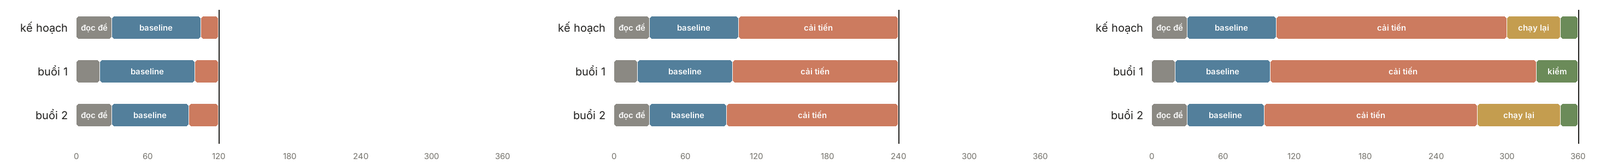

Buổi 1 dùng 225 phút cho cải thiện, đóng thí nghiệm ở phút 325 và chưa chạy lại từ đầu lần nào; 35 phút cuối đi vào sửa file lỗi. Buổi 2 chạy lại hết 70 phút, dài hơn 45 phút của kế hoạch, nên mốc đóng được dời từ phút 300 xuống 275 và vẫn còn 15 phút kiểm file. Buổi 2 có ít phút thí nghiệm hơn (180 so với 225) nhưng có bản cuối đã chạy lại được; 45 phút thí nghiệm thêm của buổi 1 không đáng giá nếu bản cuối không chạy lại được. Nếu điểm buổi 2 cao hơn, bảng này chưa cho phép gán phần tăng cho model; điều nó đo được là phần quy trình: chạy lại đủ, và phần kiểm cuối gọn từ 35 về 15 phút.

**Hỏi nhanh.** Đọc bảng nhật ký của hai buổi. Dữ liệu ủng hộ điều nào?

- A. Buổi 1 tốt hơn, vì dành nhiều phút hơn cho cải thiện
- B. Buổi 2 đóng thí nghiệm sớm hơn buổi 1 đúng 50 phút
- C. Buổi 2 kém hơn, vì phần đọc đề dài hơn buổi 1 mười phút
- D. Hai buổi như nhau, vì cả hai đều có tổng đúng 360 phút

<details><summary>Đáp án</summary>

B. Buổi 2 đóng thí nghiệm sớm hơn buổi 1 đúng 50 phút

Thời điểm đóng thí nghiệm là tổng của đọc đề, baseline và cải thiện: $30 + 65 + 180 = 275$ ở buổi 2, so với $20 + 80 + 225 = 325$ ở buổi 1, chênh 50 phút. Nhiều phút cải thiện hơn chưa chứng minh là tốt hơn, vì nhật ký không nói các thí nghiệm có giả thuyết hay không. Đọc đề dài hơn 10 phút không làm buổi 2 kém đi, khi nó vẫn chạy lại được hết và còn 15 phút để kiểm. Cùng tổng 360 phút nhưng phân bổ khác nhau, và chính phân bổ là điều cần đọc.

</details>

Khi chọn việc luyện tiếp, tách ba nhóm nguyên nhân bằng dấu hiệu:

- Không hiểu log loss hoặc thứ tự lớp: ôn kiến thức và làm một bài tính tay.
- Hiểu thuật toán nhưng chưa có validation hợp lệ: luyện thiết kế thí nghiệm theo nhóm hoặc thời gian.
- Metric tốt mà chạy lại hỏng: luyện pipeline, đóng gói tệp và đọc lại file nộp.

Một buổi sau chỉ nên chọn vài mục có thể kiểm xong, rồi giữ bài cũ làm mốc so. Không biến mọi lỗi thành yêu cầu học một model lớn hơn.

**Hỏi nhanh.** Nhật ký sau buổi thi ghi ba lần mất thời gian: nạp model ở môi trường mới thì thiếu hàm tự viết, mất 35 phút; đảo thứ tự cột khi ghép bảng, mất 20 phút; đọc nhầm hướng của metric, mất 5 phút. Nhóm nguyên nhân nào chiếm phần lớn thời gian, và nên luyện gì trước?

- A. Kiến thức, 5 phút, nên ôn định nghĩa metric bằng một bài tính tay
- B. Thực nghiệm, 20 phút, nên luyện thiết kế validation theo nhóm
- C. Quy trình, 55 phút, nên luyện nạp ở môi trường trống và đọc lại file
- D. Quy trình, 55 phút, nên thử một kiến trúc lớn hơn để bù thời gian

<details><summary>Đáp án</summary>

C. Quy trình, 55 phút, nên luyện nạp ở môi trường trống và đọc lại file

Hàm tự viết và thứ tự cột đều là lỗi của đường tạo artifact, tổng cộng $35 + 20 = 55$ trên 60 phút. Đọc nhầm hướng metric là lỗi kiến thức, nhưng chỉ mất 5 phút, và không có dòng nào nói validation sai. Model lớn hơn không sửa được việc nạp hàm hay thứ tự cột, lại còn tốn thêm thời gian chạy lại.

</details>



## Khi đi thi

- **Đọc điều kiện của đúng đề trước khi dựng bản đầu tiên.** GPU, pretrained, Internet, dạng nộp và giới hạn lượt nộp lấy từ statement của bài; điều kiện của buổi thi thử chỉ là một cấu hình luyện.
- **Đặt mốc đóng thí nghiệm bằng thời gian chạy lại đã đo.** Mốc bằng tổng thời gian trừ thời gian chạy lại từ đầu trừ thời gian kiểm file, đo trên đúng máy và đủ dữ liệu.
- **Chạy bản cuối trong môi trường trống.** Restart & Run All, hoặc một tiến trình mới trong thư mục chỉ chứa gói mang vào; hàm tự viết, tệp model và đường dẫn đều phải nằm trong gói.
- **Chọn cột và ID theo tên.** Lấy cột theo `feature_columns` trước khi chuyển sang mảng, đọc và ghi ID như chuỗi; shape đúng chưa chứng minh ghép đúng.
- **Đọc lại file thật sắp nộp.** Kiểm schema, ID, số hữu hạn, miền giá trị và hash; giữ bản đã kiểm làm dự phòng và ghi rõ bản nào đã nộp.
- **Chỉ coi hệ thống đã nhận khi chính hệ thống báo.** Receipt và hash local chỉ chứng minh bước local; sau khi nộp, đọc trạng thái nhận hoặc chấm và thông báo lỗi.

## Tóm tắt

- Thi thử đo cả năng lực lẫn quy trình, trong điều kiện ghi rõ.
- Bài làm phải chạy từ đầu trong môi trường trống; model đã lưu phải nạp được ở tiến trình mới, kể cả hàm tự viết.
- Chọn cột theo tên; ghi file nộp rồi đọc lại đúng yêu cầu; ghi hash của đúng file sẽ nộp.
- Nhật ký quyết định và thời gian giúp tìm nguyên nhân rồi chọn việc luyện tiếp.

## Kiểm tra cuối bài

**Câu 1.** Đề trắc nghiệm có 300 câu, làm trong 3 giờ. Đề ghi không trừ điểm câu sai, và không sửa được đáp án sau khi nộp. Sau 80 phút mới làm xong 100 câu. Phần còn lại cần tốc độ trung bình bao nhiêu, và nên xử lý thế nào?

- A. 36 giây mỗi câu, giữ nguyên nhịp ban đầu là đủ
- B. 30 giây mỗi câu, làm hết, để những câu dài lại quay về sau
- C. 60 giây mỗi câu, chỉ làm một nửa số câu còn lại
- D. 30 giây mỗi câu, bỏ trống câu khó vì câu sai bị trừ điểm

<details><summary>Đáp án</summary>

B. 30 giây mỗi câu, làm hết, để những câu dài lại quay về sau

Ba giờ là 10 800 giây cho 300 câu, tức 36 giây mỗi câu. Sau 80 phút còn 100 phút, tức 6000 giây cho 200 câu, nên cần 30 giây mỗi câu, nhanh hơn nhịp ban đầu, và giữ nhịp cũ là không đủ. Đề không phạt câu sai, nên bỏ trống không có lợi. Hãy điền hết, đánh dấu những câu dài để quay lại khi còn thời gian. 60 giây mỗi câu chỉ đúng nếu bỏ một nửa số câu còn lại.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Hướng dẫn làm bài](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=2)

</details>

**Câu 2.** Notebook chạy Restart & Run All thành công trên máy của đội. Trên máy chấm, cell đọc embedding báo `FileNotFoundError: ../emb/vec.npy`. Thư mục `emb` nằm cạnh thư mục dự án, và không có trong gói mang vào thi. Phép kiểm nào bắt được lỗi này trước giờ nộp?

- A. Chép gói mang vào thi sang một thư mục trống rồi chạy lại ở đó
- B. Chạy Restart & Run All thêm một lần ở thư mục dự án
- C. Đọc lại biến embedding trong RAM và so shape với bản đầu
- D. So hash của notebook với hash của lần chạy thành công trước

<details><summary>Đáp án</summary>

A. Chép gói mang vào thi sang một thư mục trống rồi chạy lại ở đó

Restart xóa trạng thái trong RAM, nhưng không đổi nơi chạy. Thư mục `emb` vẫn nằm cạnh dự án, nên lần chạy lại vẫn thành công và lỗi vẫn bị ẩn. Chỉ khi chép phần được mang vào thi sang một thư mục trống mới tái hiện được điều kiện của máy chấm. Shape của biến trong RAM và hash của chính notebook không nói gì về những file nằm ngoài gói.

</details>

**Câu 3.** Đề dữ liệu bảng chấm macro-F1. Bộ chấm chạy notebook từ trên xuống, rồi gọi `my_prediction(X_test)` với `X_test` là một DataFrame, và hàm phải trả về một `pandas.Series` chứa nhãn dự đoán. Hàm của đội trả `model.predict_proba(X_test)[:, 1]`, là một mảng NumPy. Đầu ra này sai ở đâu?

- A. Không sai, vì macro-F1 tự đổi xác suất thành nhãn khi so với đáp án
- B. Sai kiểu, nên chỉ cần bọc thành Series, vẫn giữ nguyên xác suất
- C. Sai nghĩa, nên chỉ cần đổi thành nhãn 0 hoặc 1, vẫn trả mảng NumPy
- D. Sai cả hai, cần một Series nhãn 0 hoặc 1, đúng thứ tự hàng của `X_test`

<details><summary>Đáp án</summary>

D. Sai cả hai, cần một Series nhãn 0 hoặc 1, đúng thứ tự hàng của `X_test`

Đề đòi nhãn dự đoán trong một Series, theo thứ tự hàng của `X_test`. Xác suất như 0.73 không thuộc tập nhãn, nên macro-F1 không so được. Mảng NumPy cũng không phải kiểu đề yêu cầu, nên sửa một trong hai vẫn còn lỗi kia. Ví dụ `pd.Series((p >= t).astype(int), index=X_test.index)`, với ngưỡng `t` chọn trên validation. Đây là yêu cầu của đề này, không phải quy tắc chung của mọi cuộc thi.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Problem 9](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=23)

</details>

**Câu 4.** Pipeline gồm `SimpleImputer(strategy="median")` rồi tới `StandardScaler`, đã fit trên train. Trên train, median của $x_2$ là 7. Sau khi điền thiếu, trung bình của $x_2$ là 8 và độ lệch chuẩn là 2. Một mẫu inference có $x_2$ là NaN. Giá trị $x_2$ đi vào logistic regression bằng bao nhiêu?

- A. $-0.5$, vì điền median rồi mới chuẩn hóa
- B. $0$, vì coi chỗ thiếu như đúng bằng trung bình
- C. $7$, vì chỉ điền median, chưa chuẩn hóa
- D. $-4$, vì điền 0 rồi mới chuẩn hóa

<details><summary>Đáp án</summary>

A. $-0.5$, vì điền median rồi mới chuẩn hóa

Imputer điền median 7 đã học từ train, rồi scaler dùng mean 8 và std 2 của train: $(7 - 8)/2 = -0.5$. Giá trị 7 là quên bước scaler. Giá trị 0 là coi chỗ thiếu như đúng bằng trung bình, nhưng scaler không tự điền gì cả. Giá trị $-4$ ứng với điền 0 rồi chuẩn hóa, $(0 - 8)/2$.

</details>

**Câu 5.** Đề yêu cầu, với mỗi mẫu, dự đoán tọa độ nguồn $(x_s, y_s)$ và 100 giá trị cường độ. Sai số của một mẫu là $10^3\,e_{\text{nguồn}} + 3\cdot 10^{-3}\,e_{\text{cường độ}}$, và điểm cuối là trung bình sai số của các mẫu, càng thấp càng tốt. Ô thiếu hoặc không hợp lệ ở tọa độ nguồn khiến $e_{\text{nguồn}} = 10$ cho mẫu đó. Test có 3000 mẫu. File nộp có đúng một ô NaN ở `source_y` của một mẫu, mọi ô khác hợp lệ. Điểm trung bình tăng khoảng bao nhiêu?

- A. Không đáng kể, vì chỉ là một ô trong hơn 300 000 ô của file
- B. Khoảng 0.0033, tức lấy lỗi 10 rồi chia cho 3000 mẫu
- C. Khoảng 3.3, vì mẫu đó bị tính $10^4$, chia cho 3000
- D. Khoảng 10 000, vì một mẫu bị phạt $10^4$ cộng vào tổng

<details><summary>Đáp án</summary>

C. Khoảng 3.3, vì mẫu đó bị tính $10^4$, chia cho 3000

Sai số của mẫu có ô thiếu là $10^3\cdot 10 = 10^4$, cộng thêm phần cường độ, còn điểm là trung bình trên 3000 mẫu: $10^4/3000 \approx 3.3$. Với tọa độ nằm trong $[-1, 1]$, mức phạt này nặng ngang việc đoán lệch 10 đơn vị trong khi cả miền chỉ rộng 2, dù chỉ là một ô trong 306 000 ô. 0.0033 là quên hệ số $10^3$. 10 000 là quên chia lấy trung bình. Kiểm NaN trước khi nộp là bước rẻ nhất trong cả buổi.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 1 · Problem 2](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf#page=13)

</details>

**Câu 6.** Buổi thi thử 1 và buổi 2 dùng hai đề khác nhau, và điểm buổi 2 cao hơn 0.06. Nhật ký ghi việc sửa lỗi file mất 35 phút ở buổi 1 và 5 phút ở buổi 2. Dữ liệu ủng hộ kết luận nào?

- A. Kiến thức model của đội đã tăng, nên điểm cao hơn 0.06
- B. Quy trình đã tốt hơn, bớt 30 phút sửa lỗi, nhưng chưa thể gán phần điểm cho model
- C. Buổi 2 chắc dễ hơn, nên nhật ký của hai buổi không so sánh được
- D. Điểm tăng cho thấy bản ensemble mạnh hơn bản model đơn

<details><summary>Đáp án</summary>

B. Quy trình đã tốt hơn, bớt 30 phút sửa lỗi, nhưng chưa thể gán phần điểm cho model

Thời gian sửa lỗi giảm $35 - 5 = 30$ phút là quan sát trực tiếp trong nhật ký, và nó đo quy trình. Chênh 0.06 điểm giữa hai đề khác nhau chưa tách được độ khó của đề, độ ngẫu nhiên và thay đổi của model, nên chưa thể gán cho kiến thức hay cho ensemble. Hai đề khác nhau không làm nhật ký thời gian vô nghĩa, vì lỗi file thuộc về đường nộp, không thuộc nội dung của đề.

</details>

**Câu 7.** Đề phân loại hình học ghi rằng mọi model pretrained đều bị cấm, kể cả khi không dùng trọng số pretrained, ví dụ model import từ `torchvision.models` hoặc HuggingFace. Phải tự dựng model và train từ đầu, vi phạm thì bài này được 0 điểm. Ở phút 200, đội đã train xong `torchvision.models.resnet18(weights=None)` với macro-F1 validation 0.97. Việc đúng cần làm là gì?

- A. Giữ nguyên, vì `weights=None` nghĩa là không dùng trọng số pretrained
- B. Giữ nguyên, và ghi rõ trong báo cáo rằng không nạp trọng số
- C. Dựng CNN bằng `nn.Conv2d`, train lại, rồi chạy lại từ đầu
- D. Đổi sang `timm`, vì đề chỉ nêu `torchvision` và HuggingFace

<details><summary>Đáp án</summary>

C. Dựng CNN bằng `nn.Conv2d`, train lại, rồi chạy lại từ đầu

Điều cấm nằm ở model import từ thư viện, không chỉ ở trọng số. `weights=None` vẫn là model của `torchvision.models`, nên có nguy cơ bị 0 điểm. Ghi chú trong báo cáo không thay đổi được điều đó. Danh sách trong đề chỉ là ví dụ, không phải toàn bộ, nên `timm` cũng thuộc cùng loại. Phát hiện ở phút 200 thì vẫn kịp dựng lại bằng các lớp cơ bản rồi chạy lại. Phát hiện ở phút 340 thì không kịp nữa.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 2 · Problem 4](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-2-problems.pdf#page=9)

</details>

**Câu 8.** Phút 335, bản A đã chạy lại từ đầu, đọc lại file đúng, và đã ghi hash, sẵn sàng để nộp. Bản B vừa train xong, tăng validation 0.004, cùng cỡ với dao động giữa các seed. B chưa được nạp thử ở tiến trình mới và chưa kiểm file. Chạy lại B từ đầu cần 70 phút, trong khi chỉ còn 25 phút. Chọn gì?

- A. Nộp B, vì validation cao hơn
- B. Chạy lại B từ đầu, nộp B nếu kịp, không kịp thì nộp A
- C. Nộp trung bình của A và B, vì cùng pipeline nên chưa cần nạp thử
- D. Nộp A, và ghi B vào nhật ký như một hướng thử cho buổi sau

<details><summary>Đáp án</summary>

D. Nộp A, và ghi B vào nhật ký như một hướng thử cho buổi sau

Chênh 0.004 nằm trong mức dao động giữa các seed, và B chưa có bằng chứng nào về việc chạy lại hay đọc lại file. Chạy lại cần 70 phút trong khi chỉ còn 25, nên không thể xong. Lấy trung bình hai bản là tạo ra một artifact mới chưa ai kiểm. Bản A đã đủ bằng chứng. B là một giả thuyết đáng ghi lại, chứ chưa phải bản để nộp.

</details>

**Câu 9.** Chạy lại từ đầu, bản cuối cho ra một CSV có hash khác bản đã kiểm, dù seed, code và dữ liệu giống nhau. `diff` cho thấy vài hàng khác nhau ở chữ số thứ 9 sau dấu chấm. Nên làm gì?

- A. So hai file theo dung sai và theo nhãn, rồi đọc lại bản được chọn
- B. Bỏ qua, vì khác ở chữ số thứ 9 thì coi như hash vẫn khớp
- C. Chạy lại nhiều lần cho tới khi hash khớp rồi mới nộp
- D. Nộp bản mới mà không cần kiểm, vì code và seed không đổi

<details><summary>Đáp án</summary>

A. So hai file theo dung sai và theo nhãn, rồi đọc lại bản được chọn

Hash so từng byte, nên khác ở chữ số thứ 9 vẫn là hash khác. Sai khác cỡ này thường do thứ tự cộng số thực khác nhau giữa các lần chạy, không phải lỗi logic. Cách xử lý là so theo dung sai và theo nhãn sau ngưỡng, rồi chọn một bản, đọc lại, và ghi hash của bản được chọn. Chạy tới khi trùng có thể không bao giờ xảy ra, và ăn hết thời gian. Nộp mà không kiểm là bỏ qua đúng điều mà hash được ghi để bảo vệ.

</details>

**Câu 10.** Nhật ký ở phút 250 ghi: cùng một người nói xuất hiện ở cả train lẫn validation, validation được 0.97, nhưng điểm nộp chỉ 0.71, trong khi file nộp đúng schema và ID khớp. Nhóm nguyên nhân chính là gì, và nên luyện gì tiếp?

- A. Kiến thức, nên ôn lại công thức macro-F1 bằng một bài tính tay
- B. Quy trình, nên luyện đọc lại file nộp, kiểm ID và schema
- C. Model, nên thử kiến trúc lớn hơn để thu hẹp khoảng cách điểm
- D. Thực nghiệm, nên luyện chia validation tách theo người nói

<details><summary>Đáp án</summary>

D. Thực nghiệm, nên luyện chia validation tách theo người nói

Validation chứa những người đã có trong train, nên nó đo khả năng nhận ra người, không đo khả năng tổng quát. Khoảng cách 0.97 so với 0.71 là dấu hiệu tiêu biểu. File đã đúng schema và ID, nên đường tạo artifact không phải nguyên nhân. Công thức metric không liên quan, và model lớn hơn còn ghi nhớ người nói tốt hơn.

</details>

## Đọc thêm

- [IOAI 2025 — Rules](https://ioai-official.org/wp-content/uploads/2025/08/Contest-Rules-for-IOAI-2025-version-2.3-1.pdf), mục 2.1. Đọc mô tả ngày 1 và ngày 2 của **năm 2025**, không dùng như quy định hiện hành cho mọi năm.
- [IOAI 2026 — Rules & Technical Appendix](https://ioai-official.org/wp-content/uploads/2026/06/IOAI2026-Contest-Rules-and-Tehnical-Appendix.pdf) và [repo official 2026](https://github.com/IOAI-official/IOAI-2026). Đối chiếu quy định chung với statement và môi trường của từng bài.
- [scikit-learn 1.7 — Model persistence](https://scikit-learn.org/1.7/model_persistence.html). Đọc metadata, môi trường tương thích và giới hạn của các format lưu model.
- [Python — pickle](https://docs.python.org/3/library/pickle.html). Đọc cách lưu và nạp đối tượng, và điều kiện chỉ dùng artifact đáng tin cậy.
- [Python — subprocess](https://docs.python.org/3/library/subprocess.html). Đọc `run`, timeout và xử lý lỗi cho ca chạy từ đầu.
- USA-NA-AIO 2026: đề [Vòng 1](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf), [Vòng 2 Ngày 1](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf) và [Ngày 2](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-2-problems.pdf). Đọc các mục Submission, Evaluation và Invalid Predictions của từng bài để thấy điều kiện nộp nằm trong statement.